# Dataset size ablation

Analysis of the results from running on 1k, 3k, 5k, 10k, 25k, 50k, 75k, and 100k cell datasets

In [1]:
import os
import sys
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import math
import colorcet as cc
from bs4 import BeautifulSoup
import json
import re
import glob

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

from analysis_helpers import *
import scib
from scib.metrics import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import scib
from scib.metrics import *
from analysis_helpers import *

In [3]:
# Load the HTML file
def load_html(file_path):
    with open(file_path, 'r') as f:
        html_content = f.read()

    soup = BeautifulSoup(html_content, 'html.parser')
    script_tags = soup.find_all('script')

    task_data = None
    for tag in script_tags:
        if tag.string and 'window.data =' in tag.string:
            match = re.search(r'window\.data\s*=\s*(\{.*?\});', tag.string, re.DOTALL)
            if match:
                json_text = match.group(1)
                json_text = re.sub(r'\\(?!["\\/bfnrtu])', r'\\\\', json_text)
                task_data = json.loads(json_text)
                break

    if task_data and 'trace' in task_data:
        df = pd.DataFrame(task_data['trace'])
        result_df = df[['name', 'workdir', 'status', 'peak_rss', 'duration']]
        return result_df
    else:
        print("Could not find task data in the HTML file.")
        return None

In [4]:
def make_fig(df, y, ylabel, invert=False, show_legend=False, legend_ncols=3):
    fig, ax = plt.subplots(1, 1, figsize=(1.3, 1.7))

    sns.lineplot(
        data=df, 
        x='size', 
        y=y, 
        hue='Integration', 
        marker='o', 
        markeredgewidth=0,
        markersize=2,
        linewidth=.5, 
        palette=INTEGRATION_COLOR_DICT, 
        ax=ax
    )
    if show_legend:
        sns.move_legend(
            ax, 
            "upper left", 
            bbox_to_anchor=(1, 1),
            ncols=legend_ncols,
            frameon=False,
            title="Integration",
            fontsize=5,
            title_fontsize=5,
            handlelength=1.0,
            columnspacing=0.8,
        )
    else:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    ax.patch.set_alpha(1.0)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    xticks = sorted(df['size'].unique())
    ax.set_xticks(xticks)
    ax.set_xticklabels(['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k'])
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=5)
    if invert:
        ax.invert_yaxis()
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
    for artist in ax.get_children():
        if hasattr(artist, 'get_rasterized') and artist.get_rasterized():
            print(artist, "is rasterized")
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)
    return fig, ax

In [5]:
def compute_w_across_integrations(df, metric_cols=None, id_cols=('Dataset', 'Integration', 'LabelKey', 'size')):
    if metric_cols is None:
        metric_cols = [c for c in df.columns if c not in id_cols]

    def compute_T(ranks_series):
        tie_counts = ranks_series.value_counts()
        tied = tie_counts[tie_counts > 1]
        return (tied**3 - tied).sum()

    results = []
    for metric in metric_cols:
        work = df[['Integration', 'size', metric]].copy()
        work['Rank'] = work.groupby('size')[metric].rank(ascending=False, method='average')
        pivot = work.pivot_table(index='Integration', columns='size', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)
        sum_T = pivot.apply(compute_T, axis=0).sum()

        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T
        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

## Whole benchmarking analysis

Data file: `../results/source_data/number_cells.csv`

In [6]:
df = pd.read_csv('../results/dataset_ablation/number_cells_v2/metrics/all-metrics.csv')
df

,Dataset,Integration,Metric,BatchKey,LabelKey,Value,Params
0,desimone_pbmcs_1000,clear-1,BAMI,assay,cell_type,0.619203,NaN
1,desimone_pbmcs_1000,clear-1,BRAS,assay,cell_type,0.823265,NaN
2,desimone_pbmcs_1000,clear-1,CASW,assay,cell_type,0.512591,NaN
3,desimone_pbmcs_1000,clear-1,CPCR,assay,cell_type,0.617922,NaN
4,desimone_pbmcs_1000,clear-1,ISOLISI,assay,cell_type,0.878023,NaN
...,...,...,...,...,...,...,...
1832,desimone_pbmcs_75000,sysvi-1,BRAS,assay,cell_type,0.448233,NaN
1833,desimone_pbmcs_75000,sysvi-1,CASW,assay,cell_type,0.565475,NaN
1834,desimone_pbmcs_75000,sysvi-1,CPCR,assay,cell_type,0.125363,NaN
1835,desimone_pbmcs_75000,sysvi-1,KBET,assay,cell_type,0.007309,NaN


In [7]:
df = df.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [8]:
df['BIO'] = (df['BAMI'] + df['CASW'] + df['SCGRAPHM']) / 3
df['BATCH'] = (df['CPCR'] + df['BRAS'] + df['KBET']) / 3
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [9]:
df['Integration'] = df['Integration'].str[:-2]

In [10]:
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [11]:
# Did not succeed on all data
df = df[~df['Integration'].isin(['CCA', 'Portal', 'iMAP', 'OCAT', 'UCE', 'INSCT'])]

In [12]:
df['size'] = df['Dataset'].str.split('_').str[-1].replace({
    '1000': 1, '3000': 2, '5000': 3, '10000': 4,
    '25000': 5, '50000': 6, '75000': 7, '100000': 8
})

/tmp/ipykernel_3354180/2055363870.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['size'] = df['Dataset'].str.split('_').str[-1].replace({


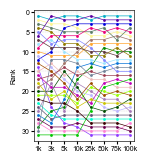

In [13]:
df['Rank'] = df.groupby(['size'])['OVERALL'].rank(ascending=False, method='min')

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'Rank', 'Rank', invert=True, show_legend=False)
#     plt.savefig('../publication_figures/num_cells_rank.svg', bbox_inches='tight')
    plt.show()

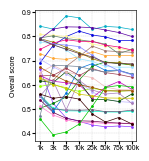

In [14]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'OVERALL', 'Overall score', invert=False, show_legend=False)
#     plt.savefig('../publication_figures/num_cells_overall.svg', bbox_inches='tight')
    plt.show()

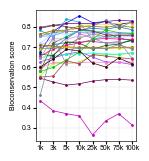

In [15]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BIO', 'Bioconservation score', invert=False, show_legend=False)
#     plt.savefig('../publication_figures/num_cells_bio.svg', bbox_inches='tight')
    plt.show()

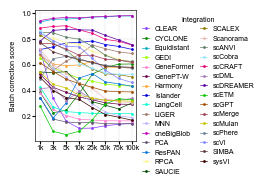

In [16]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BATCH', 'Batch correction score', invert=False, show_legend=True, legend_ncols=2)
#     plt.savefig('../publication_figures/num_cells_batch.svg', bbox_inches='tight')
    plt.show()

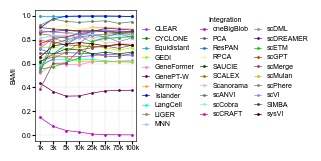

In [17]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BAMI', 'BAMI', invert=False, show_legend=True)
    plt.show()

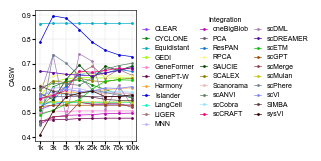

In [18]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'CASW', 'CASW', invert=False, show_legend=True)
    plt.show()

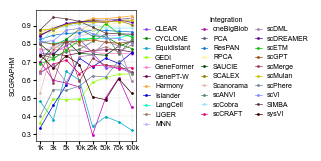

In [19]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'SCGRAPHM', 'SCGRAPHM', invert=False, show_legend=True)
    plt.show()

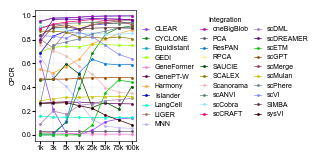

In [20]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'CPCR', 'CPCR', invert=False, show_legend=True)
    plt.show()

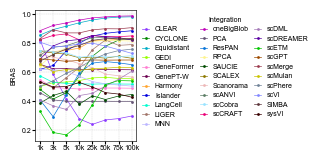

In [21]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BRAS', 'BRAS', invert=False, show_legend=True)
    plt.show()

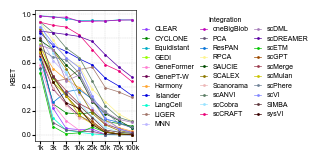

In [22]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'KBET', 'KBET', invert=False, show_legend=True)
    plt.show()

In [23]:
compute_w_across_integrations(df)

,Metric,Kendall_W
0,BAMI,0.907422
1,BRAS,0.856149
2,CASW,0.789478
3,CPCR,0.895219
4,ISOLISI,0.402043
5,KBET,0.892162
6,SCGRAPHM,0.869393
7,BIO,0.856918
8,BATCH,0.884060
9,OVERALL,0.867389


In [24]:
for i in range(1, 9):
    for j in range(i + 1, 9):
        x = df[df['size'] == i].sort_values('Integration')['Rank']
        y = df[df['size'] == j].sort_values('Integration')['Rank']
        
        print(i, j)
        print(scipy.stats.kendalltau(x, y).statistic)

1 2
0.7505376344086023
1 3
0.6688172043010753
1 4
0.5569892473118281
1 5
0.4795698924731183
1 6
0.4322580645161291
1 7
0.41505376344086026
1 8
0.40645161290322585
2 3
0.8322580645161292
2 4
0.7634408602150539
2 5
0.6516129032258065
2 6
0.6043010752688173
2 7
0.5956989247311828
2 8
0.578494623655914
3 4
0.8623655913978495
3 5
0.7333333333333334
3 6
0.6860215053763441
3 7
0.6774193548387097
3 8
0.6774193548387097
4 5
0.8365591397849462
4 6
0.789247311827957
4 7
0.7806451612903227
4 8
0.7548387096774194
5 6
0.9010752688172045
5 7
0.8752688172043012
5 8
0.849462365591398
6 7
0.9483870967741936
6 8
0.9397849462365592
7 8
0.9397849462365592


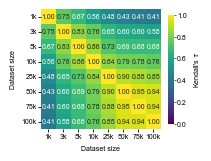

In [25]:
M = np.array([
    [1.000, 0.751, 0.669, 0.557, 0.480, 0.432, 0.415, 0.406],
    [0.751, 1.000, 0.832, 0.763, 0.652, 0.604, 0.596, 0.578],
    [0.669, 0.832, 1.000, 0.862, 0.733, 0.686, 0.677, 0.677],
    [0.557, 0.763, 0.862, 1.000, 0.837, 0.789, 0.781, 0.755],
    [0.480, 0.652, 0.733, 0.837, 1.000, 0.901, 0.875, 0.849],
    [0.432, 0.604, 0.686, 0.789, 0.901, 1.000, 0.948, 0.940],
    [0.415, 0.596, 0.677, 0.781, 0.875, 0.948, 1.000, 0.940],
    [0.406, 0.578, 0.677, 0.755, 0.849, 0.940, 0.940, 1.000],
])

with plt.rc_context({'figure.dpi': 100}):
    labels = ['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k']

    plt.figure(figsize=(2.4, 2.4))
    ax = sns.heatmap(M, annot=True, fmt=".2f", cmap="viridis",
                xticklabels=labels, yticklabels=labels,
                annot_kws={'fontsize': 5},
                vmin=0, vmax=1, square=True, cbar_kws={"label": "Kendall's $\\tau$", 'shrink': 0.6})
    
    plt.setp(ax.get_xticklabels(), fontsize=5)
    plt.setp(ax.get_yticklabels(), fontsize=5)
    cbar = ax.collections[0].colorbar
    cbar.set_label("Kendall's $\\tau$", fontsize=5)
    cbar.ax.tick_params(
        which='major', width=.45,
        length=1.5, labelsize=5, pad=1
    )
    ax.tick_params(
        axis='both', which='major', width=.6,
        length=2, labelsize=5, pad=1
    )
    plt.xticks(rotation=0) 
    ax.set_xlabel('Dataset size', fontsize=5)
    ax.set_ylabel('Dataset size', fontsize=5)
    plt.tight_layout()
#     plt.savefig('../publication_figures/dataset_size_kendall_tau_heatmap.svg', dpi=300, bbox_inches='tight')
    plt.show()

## Per-metric analysis

Complete data file: `../results/source_data/number_cells_all_metrics.csv`

In [6]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/number_cells_cpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/number_cells_gpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/number_cells_llm_methods/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/number_cells_rescue/metrics/all-metrics.csv'),
])

with open('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/rescue_list/rescue_ccc.txt', 'r') as f:
    rescue = [s.strip() for s in f.readlines()]
    
df_rescue = []
for r in rescue:
    try:
        df_rescue.append(pd.read_csv(glob.glob(r + '/*.csv')[0]))
    except:
        pass
df_rescue = pd.concat(df_rescue)
df = pd.concat([df, df_rescue])

with open('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/rescue_list/rescue_scgraph.txt', 'r') as f:
    rescue = [s.strip() for s in f.readlines()]
    
df_rescue = []
for r in rescue:
    try:
        df_rescue.append(pd.read_csv(glob.glob(r + '/*.csv')[0]))
    except:
        pass
df_rescue = pd.concat(df_rescue)
df = pd.concat([df, df_rescue])

with open('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/dataset_ablation/rescue_list/rescue_failed_metrics.txt', 'r') as f:
    rescue = [s.strip() for s in f.readlines()]
    
df_rescue = []
for r in rescue:
    try:
        df_rescue.append(pd.read_csv(glob.glob(r + '/*.csv')[0]))
    except:
        pass
df_rescue = pd.concat(df_rescue)
df = pd.concat([df, df_rescue])

target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

# Multiply the 'Value' column by -1 only for rows matching the mask
df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df["Metric"] != 'CLUSTACC']
df = df[~df.Value.isna()]
df = df.drop_duplicates(['Dataset', 'Integration', 'Metric'], keep='last')

/tmp/ipykernel_3631177/1262704212.py:41: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_rescue = pd.concat(df_rescue)


In [8]:
df.to_csv('../results/spreadsheets/number_cells_all_metrics.csv', index=False)

In [28]:
df['size'] = df['Dataset'].str.split('_').str[-1].replace({
    '1000': 1, '3000': 2, '5000': 3, '10000': 4,
    '25000': 5, '50000': 6, '75000': 7, '100000': 8
})

/tmp/ipykernel_3354180/2055363870.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['size'] = df['Dataset'].str.split('_').str[-1].replace({


In [29]:
df['Integration'] = df['Integration'].str[:-2]
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [30]:
total_unique_datasets = df['Dataset'].nunique()

df_in_all = df.groupby(['Integration']).filter(
    lambda x: x['Dataset'].nunique() == total_unique_datasets
)

In [31]:
df_sub = df_in_all
df_sub = df_sub.reset_index(drop=True)

In [32]:
bio = [
    'CCENT', 'HOMO', 'JACC', 'PURITY', 'NMIF', 'ARIF', 'BKNN', 'FKNN', 
    'MCC', 'F1', 'NNMAP', 'CNENT', 'OCS', 'KSIM', 'CLISI', 'BLOGREG', 
    'FLOGREG', 'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 
    'VI', 'FMI', 'CDBI', 'CASW', 'CCH', 'GC', 'ISOF1', 'ISOASW', 'ISOLISI',
    'CLUSTASW', 'CLUSTDBI', 'CLUSTCH', 'PSTDB', 'PPTPC', 'COMP', 'CORRMSE',
    'AGREE', 'RKNN', 'CCC', 'MORANI', 'SCGRAPH', 'SCGRAPHM', 'SCGRAPHP',
    'LDFDIFF', 'MODULARITY', 'COMPACT', 'SEPARATION'
]
batch = [
    'BASW', 'SV', 'BP', 'BCENT', 'CRE', 'BATCHARI', 'PROBELR',
    'PCR', 'CPCR', 'PROBERF', 'PROBE', 'CPROBE', 'CPROBELR', 'CPROBERF',
    'EMBDIV', 'BRAS', 'ALIGN', 'MIX', 'ILISI', 'BNENT', 'KLDIV', 'ADGBD',
    'KBETALL', 'CILISI', 'KBET', 'CSMS'
]

In [ ]:
df_sub['Rank'] = df_sub.groupby(['Metric', 'size'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = bio
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df_sub['Integration'].unique()

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3, 'hspace': 0.3})
    fig.patch.set_alpha(0.0)
    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df_sub[df_sub['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='size',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        xticks = sorted(df['size'].unique())
        ax.set_xticks(xticks)
        ax.set_xticklabels(['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k'])
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelrotation=45)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.05),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.savefig('../publication_figures/dataset_size_bio_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
df_sub['Rank'] = df_sub.groupby(['Metric', 'size'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = batch
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df_sub['Integration'].unique()

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3, 'hspace': 0.3})
    fig.patch.set_alpha(0.0)
    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df_sub[df_sub['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='size',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        xticks = sorted(df['size'].unique())
        ax.set_xticks(xticks)
        ax.set_xticklabels(['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k'])
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelrotation=45)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.0),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.savefig('../publication_figures/dataset_size_batch_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
NUM_COLS = 8
metrics = bio
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df_sub['Integration'].unique()

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3, 'hspace': 0.3})
    fig.patch.set_alpha(0.0)
    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df_sub[df_sub['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='size',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        xticks = sorted(df['size'].unique())
        ax.set_xticks(xticks)
        ax.set_xticklabels(['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k'])
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelrotation=45)
        
        if metric in ['CCH', 'CLUSTCH', 'COMPACT', 'SEPARATION']:
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.05),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.savefig('../publication_figures/dataset_size_bio_metrics_overall.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
NUM_COLS = 8
metrics = batch
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df_sub['Integration'].unique()

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3, 'hspace': 0.3})
    fig.patch.set_alpha(0.0)
    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df_sub[df_sub['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='size',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        xticks = sorted(df['size'].unique())
        ax.set_xticks(xticks)
        ax.set_xticklabels(['1k', '3k', '5k', '10k', '25k', '50k', '75k', '100k'])
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelrotation=45)
        
        if metric in ['CCH', 'CLUSTCH', 'COMPACT', 'SEPARATION']:
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.05),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.savefig('../publication_figures/dataset_size_batch_metrics_overall.png', dpi=300, bbox_inches='tight')
    plt.show()